# NeSy4PPM: Stochastic guided suffix prediction Tutorial
This notebook demonstrates how to use the NeSy4PPM framework for stochastic guided suffix prediction, specifically focused on SDFA construction, feasibility pruning, termination pruning and soft stochastic ranking.

This notebook walks through the entire NeSy4PPM pipeline, including:

    1. Data preprocessing
    2. SDFA construction
    2. Training
    3. Prediction
    4. Evaluation

# 1 Data preprocessing
The __Data preprocessing__ is responsible for loading and transforming event log into neural-compatible inputs. This phase involves:

   - `Data loading`, which involves reading the event log from the input file,
   - `Prefixes extraction`, which refers to extracting prefixes (i.e., partial trace executions) from the training log.
   - `Prefixes encoding`, which handles the conversion of input prefixes and their corresponding labels into numerical representations suitable for neural models.

In [2]:
from NeSy4PPM.Data_preprocessing.data_preprocessing import end_to_end_process
from NeSy4PPM.Data_preprocessing.utils import Encodings
from pathlib import Path

log_path = Path.cwd().parent/'data'/'input'/'logs'
log_name = "Helpdesk"
train_log = "Helpdesk_train_processed.xes"
feedback_log = "Helpdesk_feedback_processed.xes"
test_log = "Helpdesk_test_processed.xes"
encoder = Encodings.One_hot
log_data, x, y_a, _ = end_to_end_process(log_path=log_path,log_name=log_name,train_log=train_log,test_log=test_log, feedback_log=feedback_log, encoder=encoder)

parsing log, completed traces :: 100%|██████████| 763/763 [00:00<00:00, 27245.25it/s]


Total activities: 6 - Target activities: 7
	 ['Assign seriousness', 'Take in charge ticket', 'Resolve ticket', 'Closed', 'Insert ticket', 'Wait']
Num. of Training sequences: 11608
Num. of features: 6


# 2 SDFA construction
From the feedback data, we constructed SDFAs using two forms of process knowledge:

### A. Declarative knowledge:

In [4]:
from NeSy4PPM.StochasticDFA.ltlf2SDFA import Declare2SDFA

declare_model_folder= Path.cwd().parent/'data'/'input'/'SDFA'/"declarative"
feedback_log_file= Path.cwd().parent/'data'/'input'/'logs'/feedback_log
Declare2SDFA(log_data, log_name,log_path,feedback_log_file, declare_model_folder)


Initial state: 0
Accepting states: {'18'}
Number states: 20
Number transitions: 140
Wrote /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/input/SDFA/declarative/Helpdesk.sdfa
Replayed 381 traces
Preserved states: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19']
Preserved activity transitions: 120
Termination-enabled states: ['12', '16', '17', '18']
Implicit termination probabilities: tau(0)=0.000000000000, tau(1)=0.000000000000, tau(2)=0.000000000000, tau(3)=0.000000000000, tau(4)=0.000000000000, tau(5)=0.000000000000, tau(6)=0.000000000000, tau(7)=0.000000000000, tau(8)=0.000000000000, tau(9)=0.000000000000, tau(10)=0.000000000000, tau(11)=0.000000000000, tau(12)=0.000000000000, tau(13)=0.000000000000, tau(14)=0.000000000000, tau(15)=0.000000000000, tau(16)=1.000000000000, tau(17)=1.000000000000, tau(18)=1.000000000000, tau(19)=0.000000000000
Counted 1606 observed activity transitions
Counted 381 valid terminatio

### A. Procedural knowledge:

In [6]:
import os
import pm4py
import ebi
SDFA_path= log_path.parent/"SDFA"/"procedural"
os.makedirs(SDFA_path,exist_ok=True)
eventlog = pm4py.read_xes(f"{log_path}/{feedback_log}", return_legacy_log_object=True)

sdfa = ebi.convert_stochastic_deterministic_finite_automaton(eventlog)
Path(SDFA_path/f"{log_name}.sdfa").write_text(sdfa, encoding="utf-8")


parsing log, completed traces :: 100%|██████████| 381/381 [00:00<00:00, 22545.89it/s]


1635

# 3 Training
Once the prefixes are encoded, NeSy4PPM proceeds to train a neural network that learns to predict the next activity and resource given a partial trace. The training is handled via the `train` function, which takes the encoded prefix data (`x`, `y_a`, `y_g`) and builds a model according to the chosen architecture. NeSy4PPM supports two neural architectures:

- __LSTM (Long Short-Term Memory)__ networks, which are recurrent neural networks designed to handle sequential data with long-range dependencies. To use LSTM, set the `model_arch` parameter to `NN_model.LSTM`.
- __Transformer__ architectures, which use attention mechanisms to model relationships across all positions in the prefix sequence simultaneously. To use a Transformer, set the `model_arch` parameter to `NN_model.Transformer`.

Build model...
Checkpoint path: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Dreyers
Checkpoint name pattern: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Dreyers/model_{epoch:03d}-{val_loss:.3f}.keras
Epoch 1/200


DEBUG:h5py._conv:Creating converter from 5 to 3


71/71 - 1s - 14ms/step - loss: 4.4494 - val_loss: 2.2575 - learning_rate: 0.0010
Epoch 2/200
71/71 - 0s - 2ms/step - loss: 2.8238 - val_loss: 1.9889 - learning_rate: 0.0010
Epoch 3/200
71/71 - 0s - 2ms/step - loss: 2.5045 - val_loss: 1.7434 - learning_rate: 0.0010
Epoch 4/200
71/71 - 0s - 2ms/step - loss: 2.3276 - val_loss: 1.6038 - learning_rate: 0.0010
Epoch 5/200
71/71 - 0s - 2ms/step - loss: 2.1409 - val_loss: 1.5571 - learning_rate: 0.0010
Epoch 6/200
71/71 - 0s - 3ms/step - loss: 2.0348 - val_loss: 1.3920 - learning_rate: 0.0010
Epoch 7/200
71/71 - 0s - 2ms/step - loss: 1.9459 - val_loss: 1.3659 - learning_rate: 0.0010
Epoch 8/200
71/71 - 0s - 2ms/step - loss: 1.8007 - val_loss: 1.4163 - learning_rate: 0.0010
Epoch 9/200
71/71 - 0s - 2ms/step - loss: 1.7198 - val_loss: 1.3611 - learning_rate: 0.0010
Epoch 10/200
71/71 - 0s - 2ms/step - loss: 1.5736 - val_loss: 1.2454 - learning_rate: 0.0010
Epoch 11/200
71/71 - 0s - 2ms/step - loss: 1.4656 - val_loss: 1.1755 - learning_rate: 0.00

DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.font_manager:findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif-BoldItalic.ttf', name='DejaVu Serif', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', name='DejaVu Sans', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 1.05
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane

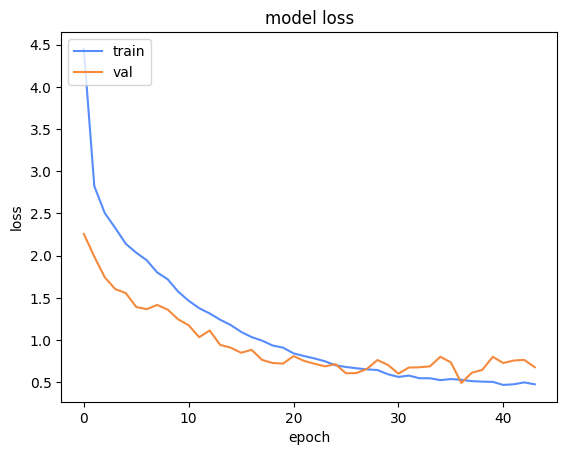

In [4]:
from NeSy4PPM.Training.train_model import train
from NeSy4PPM.Data_preprocessing.utils import NN_model

model = NN_model.Transformer
model_folder= Path.cwd().parent/'data'/'output'
train(log_data,model_arch=model,encoder= encoder, output_folder=model_folder, X=x, y_a=y_a)

# 3 Prediction:
The __SDFA-guided decoding__ in NeSy4PPM is responsible for ...

The prediction process begins by loading the SDFA file using the `load_bk` function.


In [7]:
from NeSy4PPM.Data_preprocessing.utils import load_bk

SDFA_model = load_bk(SDFA_path/f"{log_name}.sdfa")

Then run prediction process by calling `predict_evaluate` function and specifying the following parameters that control how the prediction algorithm operates:
- `beam_size`: the number of alternative suffixes explored in parallel by the beam search. A `simple autoregressive prediction` can be performed by setting `beam_size` to `1` (greedy search).
- `bk_model`: the loaded `SDFA` (procedural or declarative) model.
- `weight`: a float value in [0, 1] that balances the importance of neural predictions and stochastic probabilities. A value of 0 uses only the neural model, while higher values increase the importance of stochastic probabilities during the search.
- `BK_end`: a boolean parameter indicating whether `SDFA` is applied at the end (i.e., filtering) instead of during the search.
- `feasibility_pruning`: a boolean parameter indicating whether the feasibility pruning is performed alongside soft stochastic guidance.
- `termination_pruning`: a boolean parameter indicating whether the termination pruning is performed alongside soft stochastic guidance.

In [9]:
## SDFA-guided Prediction
from NeSy4PPM.Prediction import predict_suffix
prediction_filename = f'{log_name}_SDFA_guided_prediction.csv'
beam_size = len(log_data.act_to_int) +1  # number of activities + 1
predict_suffix.predict_evaluate(log_data, models_folder=model_folder, encoder=encoder,output_filename=prediction_filename,
                            bk_model=SDFA_model, beam_size=beam_size, weight=0.5, bk_end=False, termination_pruning=True, feasibility_pruning=True)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk/model_049-0.288.keras


  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/Desktop/NeSy4PPM/NeSy4PPM/Prediction/prepare_data.py:222: RuntimeWarning: divide by zero encountered in log
  score = (np.log(prediction) * (1 - weight)) + (np.log(BK_res) * weight)
 32%|███▏      | 241/763 [00:00<00:00, 690.53it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 1489.67it/s]


['Case 1001_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 0.2890608310699463, 22]
['Case 1007_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 0.2890608310699463, 22]
['Case 1019_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 0.2890608310699463, 22]
['Case 1023_test', 1, 'Assign seriousness', 'Resolve ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.5, 0.2890608310699463, 22]
['Case 1027_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 0.2890608310699463, 22]
['Case 1038_test', 1, 'Assign seriousness', 'Take in cha

  0%|          | 0/763 [00:00<?, ?it/s]

['Case 1001_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 0.2890608310699463, 22]
['Case 1007_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 0.2890608310699463, 22]


/Users/jamilaoukharijane/Desktop/NeSy4PPM/NeSy4PPM/Prediction/prepare_data.py:222: RuntimeWarning: divide by zero encountered in log
  score = (np.log(prediction) * (1 - weight)) + (np.log(BK_res) * weight)
 32%|███▏      | 241/763 [00:00<00:00, 801.03it/s]

... (13 outputs left out)

/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 2626.44it/s]


['Case 2598_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 2599_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.019716262817382812, 2]
['Case 2603_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 2607_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 2609_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.019716262817382812, 2]
['Case 2611_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.019716262817382812, 2]
['Case 2614_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.0

  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 9498.42it/s]

['Case 1001_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 1007_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 1019_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.019716262817382812, 2]
['Case 1023_test', 3, 'Assign seriousness>>Resolve ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.016540050506591797, 2]
['Case 1027_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.019716262817382812, 2]
['Case 1038_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.08000516891479492, 6]
['Case 1043_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.01971626281738

In [10]:
## SDFA_nopruning Prediction
from NeSy4PPM.Prediction import predict_suffix
prediction_filename = f'{log_name}_SDFA_nopruning_prediction.csv'
beam_size = len(log_data.act_to_int) +1  # number of activities + 1
predict_suffix.predict_evaluate(log_data, models_folder=model_folder, encoder=encoder,output_filename=prediction_filename,
                            bk_model=SDFA_model, beam_size=beam_size, weight=0.5, bk_end=False, termination_pruning=False, feasibility_pruning=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk/model_049-0.288.keras


  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/Desktop/NeSy4PPM/NeSy4PPM/Prediction/prepare_data.py:222: RuntimeWarning: divide by zero encountered in log
  score = (np.log(prediction) * (1 - weight)) + (np.log(BK_res) * weight)
  0%|          | 2/763 [00:01<11:32,  1.10it/s]

['Case 1001_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 1.7678661346435547, 133]
['Case 1007_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 1.7678661346435547, 133]
['Case 1019_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 1.7678661346435547, 133]
['Case 1023_test', 1, 'Assign seriousness', 'Resolve ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.5, 1.7678661346435547, 133]
['Case 1027_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 1.7678661346435547, 133]
['Case 1038_test', 1, 'Assign seriousness', 'Take i

 32%|███▏      | 241/763 [00:04<00:08, 61.13it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:04<00:00, 168.27it/s]


['Case 2259_test', 1, 'Insert ticket', 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Closed', 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 2.6147470474243164, 196]
['Case 2267_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 1.7678661346435547, 133]
['Case 2268_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.5, 1.7678661346435547, 133]
['Case 2279_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 1.7678661346435547, 133]
['Case 2290_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.5, 1.7678661346435547, 133]
['Case 2296_test', 1, 'Assign s

  0%|          | 0/763 [00:00<?, ?it/s]

... (29 outputs left out)

 32%|███▏      | 241/763 [00:03<00:04, 111.86it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:03<00:00, 206.31it/s]


['Case 2259_test', 4, 'Insert ticket>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.666637659072876, 49]
['Case 2267_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 49]
['Case 2268_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7040088176727295, 49]
['Case 2279_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 49]
['Case 2290_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 49]
['Case 2296_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7040088176727295, 49]
['Case 22_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0,

  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 9790.30it/s]

['Case 1001_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7040088176727295, 49]
['Case 1007_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7040088176727295, 49]
['Case 1019_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 49]
['Case 1023_test', 3, 'Assign seriousness>>Resolve ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.688532829284668, 49]
['Case 1027_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 49]
['Case 1038_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7040088176727295, 49]
['Case 1043_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.5, 0.7160379886627197, 

In [11]:
## Neural-only Prediction
from NeSy4PPM.Prediction import predict_suffix
prediction_filename = f'{log_name}_neural_prediction.csv'
beam_size = len(log_data.act_to_int) +1  # number of activities + 1
predict_suffix.predict_evaluate(log_data, models_folder=model_folder, encoder=encoder,output_filename=prediction_filename,
                            bk_model=None, beam_size=beam_size, weight=0.0, bk_end=False, termination_pruning=False, feasibility_pruning=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk/model_049-0.288.keras


  0%|          | 2/763 [00:01<12:15,  1.03it/s]

['Case 1001_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 1.8819169998168945, 140]
['Case 1007_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 1.8819169998168945, 140]
['Case 1019_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.8819169998168945, 140]
['Case 1023_test', 1, 'Assign seriousness', 'Resolve ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8819169998168945, 140]
['Case 1027_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.8819169998168945, 140]
['Case 1038_test', 1, 'Assign seriousness', 'Take i

 32%|███▏      | 241/763 [00:03<00:07, 73.74it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:03<00:00, 195.75it/s]


['Case 2259_test', 1, 'Insert ticket', 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.864293098449707, 140]
['Case 2267_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.8819169998168945, 140]
['Case 2268_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 1.8819169998168945, 140]
['Case 2279_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.8819169998168945, 140]
['Case 2290_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 1.8819169998168945, 140]
['Case 2296_test', 1, 'Assign seriousness', 'Take 

  0%|          | 0/763 [00:00<?, ?it/s]

... (29 outputs left out)

 32%|███▏      | 241/763 [00:03<00:04, 107.84it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:03<00:00, 199.53it/s]


['Case 2259_test', 4, 'Insert ticket>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.703559160232544, 49]
['Case 2267_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666, 49]
['Case 2268_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6919538974761963, 49]
['Case 2279_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666, 49]
['Case 2290_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666, 49]
['Case 2296_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6919538974761963, 49]
['Case 22_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0,

  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 9457.35it/s]

['Case 1001_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6919538974761963, 49]
['Case 1007_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6919538974761963, 49]
['Case 1019_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666, 49]
['Case 1023_test', 3, 'Assign seriousness>>Resolve ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024021148681641, 49]
['Case 1027_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666, 49]
['Case 1038_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6919538974761963, 49]
['Case 1043_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7396700382232666,

In [12]:
## SDFA post-decoding Prediction
from NeSy4PPM.Prediction import predict_suffix
prediction_filename = f'{log_name}_SDFA_postdecoding_prediction.csv'
beam_size = len(log_data.act_to_int) +1  # number of activities + 1
predict_suffix.predict_evaluate(log_data, models_folder=model_folder, encoder=encoder,output_filename=prediction_filename,
                            bk_model=SDFA_model, beam_size=beam_size, weight=0.0, bk_end=True, termination_pruning=False, feasibility_pruning=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/NeSy4PPM/docs/source/data/output/models/CF/Helpdesk/model_049-0.288.keras


  0%|          | 2/763 [00:02<17:32,  1.38s/it]

['Case 1001_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 2.715691089630127, 210]
['Case 1007_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 2.715691089630127, 210]
['Case 1019_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 2.715691089630127, 210]
['Case 1023_test', 1, 'Assign seriousness', 'Resolve ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 2.715691089630127, 210]
['Case 1027_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 2.715691089630127, 210]
['Case 1038_test', 1, 'Assign seriousness', 'Take in cha

 32%|███▏      | 241/763 [00:05<00:09, 53.58it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:05<00:00, 142.03it/s]


['Case 2259_test', 1, 'Insert ticket', 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Closed', 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 2.5045130252838135, 217]
['Case 2267_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 2.715691089630127, 210]
['Case 2268_test', 1, 'Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 2.715691089630127, 210]
['Case 2279_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 2.715691089630127, 210]
['Case 2290_test', 1, 'Assign seriousness', 'Take in charge ticket>>Wait>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 0.75, 0.75, 0.0, 2.715691089630127, 210]
['Case 2296_test', 1, 'Assign serio

  0%|          | 0/763 [00:00<?, ?it/s]

... (29 outputs left out)

 32%|███▏      | 241/763 [00:04<00:05, 100.60it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:04<00:00, 173.82it/s]


['Case 2259_test', 4, 'Insert ticket>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.6851189136505127, 91]
['Case 2267_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024219036102295, 91]
['Case 2268_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.3181838989257812, 112]
['Case 2279_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024219036102295, 91]
['Case 2290_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024219036102295, 91]
['Case 2296_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.3181838989257812, 112]
['Case 22_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1

  0%|          | 0/763 [00:00<?, ?it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 763/763 [00:00<00:00, 9397.81it/s]

['Case 1001_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.3181838989257812, 112]
['Case 1007_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.3181838989257812, 112]
['Case 1019_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024219036102295, 91]
['Case 1023_test', 3, 'Assign seriousness>>Resolve ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.291191816329956, 112]
['Case 1027_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.7024219036102295, 91]
['Case 1038_test', 3, 'Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.3181838989257812, 112]
['Case 1043_test', 4, 'Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.70242190361022

# 4 Evaluation
The __evaluation__ assesses the performance of the prediction by computing a variety of metrics, including:

- `Time`: defined as the average computational time required to generate a predicted suffix.
- `Damerau-Levenshtein similarity`: Computes the Damerau-Levenshtein similarity between predicted and ground-truth sequences of activities.
- `Feasibility`: defined as the proportion of predicted suffixes whose activities follow admissible SDFA transitions from the replay state reached by their observed prefixes.
-  `Termination`: defined as the proportion of predicted suffixes that are feasible and end in a state with non-zero termination probability.
- `nEBC (Normalized Explored Branch Count)`: defined as the normalized number of explored branches during suffix prediction, which quantifies the effective search space explored by each method.

In [13]:
import pandas as pd
from NeSy4PPM.Evaluation import evaluate_all

metrics = ["Time", "Damerau-Levenshtien similarity", "SDFA Conformance", "nEBC"]
methods = ["neural","SDFA_postdecoding", "SDFA_nopruning", "SDFA_guided"]

output_folder= Path.cwd().parent/'data'/'output'/"results"/"CF"
# Get min and max of explored branch under all methods
def collect_rbc_values(output_folder, methods):
    rbc_values = []
    for method in methods:
        prediction_filename = f'{log_name}_{method}_prediction.csv'
        file_path = os.path.join(output_folder, prediction_filename)
        if not os.path.exists(file_path):
            return []

        df_results = pd.read_csv(file_path, delimiter=',')
        if "EBC" not in df_results.columns:
            return []
        EBC_values = pd.to_numeric(df_results["EBC"], errors="coerce")
        rbc_values.extend(EBC_values)
    return min(rbc_values), max(rbc_values)

rbc_min, rbc_max = collect_rbc_values(output_folder=output_folder, methods=methods)

for method in methods:
    print(f"Method: {method}")
    w = 0.0 if method in ["neural", "SDFA_postdecoding"] else 0.5
    prediction_filename = f'{log_name}_{method}_prediction.csv'
    metrics_results = evaluate_all(output_folder=output_folder, filename=prediction_filename, metrics=metrics,
                                           sdfa_model=SDFA_model["model"], weight=w,
                                           rbc_min=rbc_min, rbc_max=rbc_max)
    print("Time",metrics_results["Time"])
    print("Damerau-Levenshtien similarity", metrics_results["Damerau-Levenshtien similarity"]["Activities"])
    print("Feasibility", metrics_results["SDFA Conformance"]["feasibility_rate"])
    print("Termination",metrics_results["SDFA Conformance"]["termination_rate"])
    print("nEBC",metrics_results["nEBC"],"\n")


Method: neural
Time 1.248
Damerau-Levenshtien similarity 0.91
Feasibility 1.0
Termination 1.0
nEBC 0.429 

Method: SDFA_postdecoding
Time 1.776
Damerau-Levenshtien similarity 0.91
Feasibility 1.0
Termination 1.0
nEBC 0.701 

Method: SDFA_nopruning
Time 1.204
Damerau-Levenshtien similarity 0.936
Feasibility 1.0
Termination 1.0
nEBC 0.401 

Method: SDFA_guided
Time 0.153
Damerau-Levenshtien similarity 0.936
Feasibility 1.0
Termination 1.0
nEBC 0.043 

